## Import Libraries

In [1]:
## import libraries

import matplotlib.pyplot as plt
import numpy as np
import os
import json
import pandas as pd
import sys

from matplotlib import colormaps, cm
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from matplotlib.text import Text

import seaborn as sns
import itertools
import math
from matplotlib.gridspec import GridSpec

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Ensure the src directory is in the Python path
src_dir = os.path.abspath("../src")
if src_dir not in sys.path:
    sys.path.append(src_dir)

import pnetwork.sow as sow
import pnetwork.utils as utils

## Figure parameters

In [2]:
## data path or read in data

setup_file = "../data/processed/setup.json"

# Figure 5
fig5_swmm_path = "../results/SOWs_output/" 
fig5_network = "84" 
fig5_figure_name = "Figure5.pdf"

# Figure 6
fig6_n_obj = 4
fig6_network = ["5", "9", "16", "23", "37", "49", "62", "76", "84", "100", "150", "200"]
fig6_swmm_folder = "../results/SOWs_output/"
fig6_figure_name = "Figure6.pdf"


# Figure 7
fig7_n_obj = 2
fig7_network = "37"
fig7_UDD = True
fig7_UDD_20prec = True
fig7_swmm_folder = "../results/SOWs_output/"


fig7_figure_name = "Figure7.pdf"
fig7_paths = {'SystemSF': "../results/SOWs_output/37/SystemSF_4obj/pf.csv",
                'PBP': "../results/SOWs_output/37/PipeByPipe_4obj/pop_740_ftol_0.005/pf.csv",
                'FunctionSF': "../results/SOWs_output/37/FunctionSF_4obj/pf.csv"}

# Figure 8
fig8_swmm_folder = '../results/SOWs_output/'
fig8_network = '37'
fig8_results_path = {'SF': 'SystemSF_4obj/pf.csv',
                     'Pipe-by-Pipe': 'PipeByPipe_4obj/pop_740_ftol_0.005/pf.csv',
                     'FunctionSF': 'FunctionSF_4obj/pf.csv'}
fig8_report = 90

obj_name = ['Reliability (%)',   'Overflow volume (k $ft^3$)', 'Robustness (%)','Cost ($/ft)'] #need to change order when reading in Standard design data
columns_axes = obj_name
axis_labels = [ 'Reliability\nAgainst Design Storms\n(%)', 
               'System\nOverflow Volume\n(k $ft^3$)',   'Robustness Against\nDeep Uncertainties\n(%)', 'Upfront Cost\n($/ft)']
ideal_direction = 'top'
minmaxs = [ 'max','min', 'max', 'min']
fig8_figure_name = "Figure8.pdf"


# Figure 9
fig9_sobol_json_path_all = "../results/SOWs_output/sobol/sobol_analysis_network_37_aggregated_65536_seed_1.json"
fig9_sobol_json_path = "../results/SOWs_output/sobol/sobol_analysis_network_37_65536_seed_1.json"
fig9_figure_name = "Figure9.pdf"

## Source code / Functions

### Figure 5

In [3]:
# Figure 5
def plot_stress_test(setup, swmm_path, network, figure_name, num_sample = None, rel=80):
    """
    Plot reliability results for a network under stress test scenarios.

    Args:
        setup (str): Path to UDD setup JSON file.
        swmm_path (str): Path for the results folder.
        network (str): Network ID to evaluate.
        figure_name (str): Path and filename to save the figure.
        num_sample (int, optional): Number of samples per scenario (default: None). Needed if --_conv_folder is True
        rel (float): Reliability threshold for robustness.
    """
    setup_data = utils.load_json(setup)
    climate_models = setup_data["climate_models"]
    aging_models = setup_data["aging_models"]
    num_scenario = len(climate_models) * len(aging_models)

    reliability_list = []
    # Load the precomputed evaluation results
    file_path = os.path.join(swmm_path, network, "udd_eval_results.npy")
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        return

    data = np.load(file_path, allow_pickle=True)
    num_sample = int(data.shape[0] / num_scenario)
    print(f"Number of scenarios: {num_scenario}, Number of samples per scenario: {num_sample}")

    
    for group_idx in range(num_scenario):
        start_idx = group_idx * num_sample
        end_idx = (group_idx + 1) * num_sample
        reliability, _, _ = sow.read_result(
            data[start_idx:end_idx],
            num_sample=num_sample,
            num_all_sample=num_sample,
            rel=rel
        )
        reliability_list.append(reliability)
    
        

    # Compute and print average reliability
    avg_reliability = sum(reliability_list) / num_scenario
    print(f"Average reliability: {avg_reliability}")
    print(f"Reliability list: {reliability_list}")

    plot_scenarios_scatter_one_row(
        reliability_list,
        xlabel='Estimated Reliability (%) against 24-hr 10-yr rainfall events in 2075',
        fig_name=figure_name
    )


def plot_scenarios_scatter_one_row(values, xlabel, fig_name):
    """
    Create a horizontal scatter plot for scenario reliability values.

    Args:
        values (list): List of reliability values for each scenario.
        xlabel (str): Label for the x-axis.
        fig_name (str): Path (without extension) to save the figure.
    """
    plt.figure(figsize=(10, 2))
    y_positions = 1

    plt.yticks([])  # Hide y ticks
    plt.scatter(values, [y_positions] * len(values), color='red', alpha=0.7, s=80)

    # Claimed performance (green line + text)
    plt.axvline(x=100, color='green', linestyle='-')
    plt.annotate(
        '',
        xy=(100, 1.5), xytext=(100, 1.7),
        arrowprops=dict(facecolor='green', edgecolor='green', arrowstyle='->'),
    )
    plt.text(85, 1.7, 'Neglecting climate change\n& uncertainties', 
             fontsize=14, color='green', ha='center')

    # Stress-test results (red arrow + text)
    plt.annotate(
        'Scenarios considering\nclimate change & deep uncertainties',
        xy=(37, 1.3), xytext=(37, 1.6),
        arrowprops=dict(facecolor='red', edgecolor='red', arrowstyle='->'),
        fontsize=14, color='red', ha='center'
    )

    plt.xlabel(xlabel, fontsize=14)
    plt.xticks(fontsize=14)
    plt.xlim(-2, 102)
    plt.ylim(0.5, 1.5)
    plt.grid(True, which='both', linestyle=':', linewidth=1.5)
    plt.savefig(fig_name, bbox_inches='tight')
    plt.show()
    plt.close()

### Figure 6

In [4]:
# Figure 6

def BruteForce_estimation(runtimes, networks, swmm_folder, n_choices=6):
    """
    Estimate runtimes for BruteForce based on the number of pipes.

    Args:
        runtimes (list): List of recorded runtimes for different networks.
        networks (list): List of network names.
        n_choices (int): Number of choices per pipe (default: 6).

    Returns:
        list: Estimated runtimes for BruteForce.
    """
    one_simulation_runtimes = []
    for i in networks:
        udd_path = os.path.join(swmm_folder, i, 'UDD', 'udd.json')
        if os.path.exists(udd_path):
            with open(udd_path, 'r') as f:
                data = json.load(f)
                one_simulation_runtimes.append(data['runtime_swmm'])
        else:
            print(f"Warning: {udd_path} does not exist.")
            return False

    # Take the first network as the base case
    base_runtime = runtimes[0] if runtimes else 0.1   # Avoid division
    base_one_simulation_runtime = one_simulation_runtimes[0] if one_simulation_runtimes else 0.1  # Avoid division

    # Calculate the number of designs for the base case
    base_network = int(networks[0]) if networks else 5
    base_designs = n_choices ** base_network

    # Calculate the estimated runtime for one base case design
    estimated_one_simulation_runtime = base_runtime / base_designs 

    # Calculate the ratio of one simulation runtime
    ratio = estimated_one_simulation_runtime / base_one_simulation_runtime


    # Calculate the number of designs for each network
    designs = [n_choices ** int(network) for network in networks]
    start_idx = len(runtimes)
    estimated_runtimes = [design * ratio * network_runtime for design, network_runtime in zip(designs[start_idx:], one_simulation_runtimes[start_idx:])]
    return list(runtimes) + estimated_runtimes


def approaches_estimation(runtimes, networks):
    """
    Estimate runtimes for different approaches based on the number of pipes using linear regression for log-log scaling.

    Args:
        runtimes (list): List of recorded runtimes for different networks.
        networks (list): List of network names.

    Returns:
        list: Estimated runtimes for each approach.
    """
    pipe_counts = [int(n) for n in networks[:len(runtimes)]]
    # Fit a linear regression (log-log for better scaling)
    log_pipes = np.log(pipe_counts)
    log_runtimes = np.log(runtimes)
    coeffs = np.polyfit(log_pipes, log_runtimes, 1)
    # Predict for all networks
    all_pipe_counts = [int(n) for n in networks]
    log_pred = coeffs[0] * np.log(all_pipe_counts) + coeffs[1]
    predicted_runtimes = np.exp(log_pred).tolist()
    start_idx = len(runtimes)
    return runtimes + predicted_runtimes[start_idx:]


def plot_runtime(n_obj, network, swmm_folder, figure_name):
    """
    Plot the runtime for different approaches.

    Args:
        n_obj (int): Number of objectives.
        network (list): List of network names.
        swmm_folder (str): Folder containing SWMM results.
        figure_name (str): Name of the figure file to save.
    """
    runtimes = np.zeros((len(network), 5), dtype=float)

    BruteForce, PipeByPipe, SystemSF, FunctionSF, UDD = 0, 5, 9, 9, 0 # Number of networks to plot by each approach

    runtimes_recorded = pd.read_csv(os.path.join(swmm_folder, f"runtimes_{n_obj}obj.csv"), index_col=0, header=0).to_numpy()

    runtimes[:runtimes_recorded.shape[0], :] = runtimes_recorded


    # Estimate runtimes for BruteForce
    runtimes[:UDD, 0] = BruteForce_estimation(runtimes[:BruteForce, 0].tolist(), network[:UDD], swmm_folder)
    # Estimate runtimes for other approaches
    runtimes[:, 1] = approaches_estimation(runtimes[:PipeByPipe, 1].tolist(), network)
    runtimes[:, 2] = approaches_estimation(runtimes[:SystemSF, 2].tolist(), network)
    runtimes[:, 3] = approaches_estimation(runtimes[:FunctionSF, 3].tolist(), network)

    # Print runtimes
    print("The runtime difference for different approaches (seconds):")
    runtimes_ratio = np.zeros((len(network), 3), dtype=float)
    for i in range(len(network)):
        print(f"Network {network[i]}: BruteForce: {runtimes[i,0]:.2f}, PipeByPipe: {runtimes[i,1]:.2f}, SystemSF: {runtimes[i,2]:.2f}, FunctionSF: {runtimes[i,3]:.2f}")
        runtimes_ratio[i, 0] = runtimes[i,1] / runtimes[i,2]
        runtimes_ratio[i, 1] = runtimes[i,1] / runtimes[i,3]
        runtimes_ratio[i, 2] = runtimes[i,3] / runtimes[i,2]
    print("The runtime ratio for different approaches (times):")
    for i in range(len(network)):
        print(f"Network {network[i]}: PipeByPipe/SystemSF: {runtimes_ratio[i,0]:.2f}, PipeByPipe/FunctionSF: {runtimes_ratio[i,1]:.2f}, FunctionSF/SystemSF: {runtimes_ratio[i,2]:.2f}")
    print("The average runtime ratio for different approaches (times):")
    print(f"PipeByPipe/SystemSF: {runtimes_ratio[:,0].mean():.2f}, PipeByPipe/FunctionSF: {runtimes_ratio[:,1].mean():.2f}, FunctionSF/SystemSF: {runtimes_ratio[:,2].mean():.2f}")
    
    # Plotting
    y_min = 1
    y_max = 1e10

    fig, ax1 = plt.subplots(figsize=(12, 12/1.618))
    
    method_names = ['BruteForce', 'PipeByPipe', 'SystemSF', 'FunctionSF']
    colors = ['red', 'blue', 'orange', 'purple']
    markers = ['o', 'o', 'o', 'o']
    markers_size = [12,12,12,12]

    x = [int(n) for n in network]

    for idx, method in enumerate(method_names):
        if method == 'BruteForce':
            real_n = BruteForce
        elif method == 'PipeByPipe':
            real_n = PipeByPipe
        elif method == 'SystemSF':
            real_n = SystemSF
        elif method == 'FunctionSF':
            real_n = FunctionSF
        
        # Plot actual data line (solid)
        if real_n > 0:
            if method == 'BruteForce':
                ax1.plot(x[:real_n], runtimes[:real_n, idx], 
                        linestyle='-', color=colors[idx], linewidth=3, alpha=0.8)
            else:
                ax1.plot(x[:real_n], runtimes[:real_n, idx], 
                        linestyle='-', color=colors[idx], linewidth=3, alpha=0.8)
        
        # Plot estimated data line (dashed)
        if method == 'BruteForce':
            if real_n < UDD:
                ax1.plot(x[real_n-1:UDD], runtimes[real_n-1:UDD, idx], 
                        linestyle='--', color=colors[idx], linewidth=3, alpha=0.8)
        else:
            if real_n < len(x):
                ax1.plot(x[real_n-1:], runtimes[real_n-1:, idx], 
                        linestyle='--', color=colors[idx], linewidth=3, alpha=0.8)
        
        # Plot actual data points (filled markers)
        if real_n > 0:
            ax1.scatter(x[:real_n], runtimes[:real_n, idx], 
                       marker=markers[idx], s=markers_size[idx]*8, 
                       color=colors[idx], edgecolors='black', linewidth=1,
                       zorder=5)
        
        # Plot estimated data points (hollow markers)
        if method == 'BruteForce':
            if real_n < UDD:
                ax1.scatter(x[real_n:UDD], runtimes[real_n:UDD, idx], 
                           marker=markers[idx], s=markers_size[idx]*8, 
                           facecolors='none', edgecolors=colors[idx], 
                           linewidth=2, zorder=5)
        else:
            if real_n < len(x):
                ax1.scatter(x[real_n:], runtimes[real_n:, idx], 
                           marker=markers[idx], s=markers_size[idx]*8, 
                           facecolors='none', edgecolors=colors[idx], 
                           linewidth=2, zorder=5)
                
    
    # Add legend
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
                   markeredgecolor='black', markersize=10, linewidth=0, 
                   label='Observed'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='none', 
                   markeredgecolor='gray', markersize=10, linewidth=0, 
                   markeredgewidth=1, label='Estimated')
    ]
    ax1.legend(handles=legend_elements, fontsize=18, loc='upper left', 
                   bbox_to_anchor=(0.06, 0.98))
    
    
    # Position labels at strategic points along each curve
    label_positions = {
        'BruteForce': (x[1], runtimes[1, 0]),
        'PipeByPipe': (x[4]+30, runtimes[4, 1] + 1000000),  
        'SystemSF': (x[6]+20, runtimes[6, 2]-2500),
        'FunctionSF': (x[7]+17, runtimes[7, 3]-55000)
    }

    for idx, method in enumerate(method_names):
        pos_x, pos_y = label_positions[method]
        if method == 'BruteForce':
            ax1.annotate('Brute Force', xy=(pos_x, pos_y), xytext=(10, 10), 
                        textcoords='offset points', fontsize=18, fontweight='bold',
                        color=colors[idx])
        elif method == 'PipeByPipe':
            ax1.annotate('Pipe by Pipe', xy=(pos_x, pos_y), xytext=(10, 10), 
                        textcoords='offset points', fontsize=18, fontweight='bold',
                        color=colors[idx])
        else:
            ax1.annotate(method, xy=(pos_x, pos_y), xytext=(10, 10), 
                        textcoords='offset points', fontsize=18, fontweight='bold',
                        color=colors[idx])


    ax1.text(37, 3, '(a)\nMain Test:\n37 pipes', fontsize=18, ha='center', va='bottom', color='black')
    ax1.text(84, 3, '(b)\nStress Test:\n84 pipes', fontsize=18, ha='center', va='bottom', color='black')
    ax1.annotate('', xy=(37, 1), xytext=(37, 3), arrowprops=dict(arrowstyle='->', color='black'))
    ax1.annotate('', xy=(84, 1), xytext=(84, 3), arrowprops=dict(arrowstyle='->', color='black'))

    ax1.set_yscale('log')
    ax1.set_ylim(y_min, y_max)
    ax1.set_xlim(4.25, 240)
    ax1.set_xscale('log')
    ax1.tick_params(axis='y', labelsize=20)
    ax1.set_xticks([5, 10, 20, 50, 100, 150, 200])
    ax1.set_xticklabels(['5', '10', '20', '50', '100', '150', '200'], fontsize=20)
    ax1.fill_betweenx([0, 31*24*3600], 1, 250, color='lightgreen', alpha=0.2)
    ax1.text(7, 10**6, 'Under one month', fontsize=18, ha='center', va='center', color='green', alpha=0.6)
    

    ax1.set_xlabel("Number of Pipes (log-scale)", fontsize=20)
    ax1.set_ylabel("Wall Time (log-scale, seconds)", fontsize=20)

    # Create a twin y-axis for the second set of y-values
    ax2 = ax1.twinx()
    ax2.set_yscale('log')
    ax2.set_ylim(y_min, y_max)
    ax2.set_yticks([1, 60, 3600, 24*3600, 7*24*3600, 31*24*3600, 365*24*3600])
    ax2.set_yticklabels(['1 second', '1 min', '1 hour', '1 day', '1 week', '1 month', '1 year'], fontsize=20)
    ax2.tick_params(axis='y', labelcolor='black')
    
    plt.tight_layout()
    plt.savefig(figure_name, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

### Figure 7

In [5]:
def pf_df(df, objs, mins = [0,1]):
    # Filter the DataFrame with rows that are Pareto-optimal based on the objectives in 'objs'.
    # if mins[i] is 1, then the objectives are to be minimized. If 0, then the objectives are to be maximized.
    """
    Args:
        df (pd.DataFrame): Input DataFrame containing the data.
        objs (list): List of objective column names to consider for Pareto filtering.
        mins (list, optional): List indicating whether to minimize (1) or maximize (0) each objective. Defaults to [0, 1].
    Returns:
        pd.DataFrame: Filtered DataFrame containing only Pareto-optimal rows.
    """
    values = df[objs].to_numpy()
    n = len(values)
    is_pareto = np.ones(n, dtype=bool)

    for i in range(n):
        if not is_pareto[i]:
            continue

        for j in range(n):
            if i == j:
                continue

            better_or_equal = True
            strictly_better = False

            for k, minimize in enumerate(mins):
                if minimize == 1:
                    if values[j, k] > values[i, k]:
                        better_or_equal = False
                        break
                    if values[j, k] < values[i, k]:
                        strictly_better = True
                else:
                    if values[j, k] < values[i, k]:
                        better_or_equal = False
                        break
                    if values[j, k] > values[i, k]:
                        strictly_better = True

            if better_or_equal and strictly_better:
                is_pareto[i] = False
                break

    return df[is_pareto].copy()

def read_result(path, n_obj, objs, sf_name = [], negative = True, 
                cost_per_ft = True, total_length = 1, report=False):
    """
    Read optimization results from a CSV file and process the data for plotting.

    Args:
        path (str): Path to the CSV file containing optimization results.
        n_obj (int): Number of objectives in the optimization problem.
        objs (list): List of objective names corresponding to the columns in the CSV.
        sf_name (list, optional): List of additional column names for system/function safety factors (default: []).
        negative (bool, optional): Whether to negate reliability and robustness values (default: True).
        cost_per_ft (bool, optional): Whether to calculate cost per foot instead of total cost (default: True).
        total_length (float, optional): Total length of the pipes for cost per foot calculation (default: 1).
        report (float or bool, optional): If a float is provided, it represents a reliability threshold for reporting a specific design. If False, no specific design is reported (default: False).
    """
    
    data = pd.read_csv(path)
    ocols = [f"f{i+1}" for i in range(n_obj)]
    if len(sf_name) == 0:
        df = pd.DataFrame(data, columns= ocols)
    else:
        df = pd.DataFrame(data, columns= ocols + sf_name)
    cols_rename = {ocols[i]: objs[i] for i in range(n_obj)}
    df.rename(columns = cols_rename, inplace=True)
    if negative:
        df['Reliability (%)'] = -df['Reliability (%)']
        if 'Robustness (%)' in df.columns:
            df['Robustness (%)'] = -df['Robustness (%)']
    if cost_per_ft:
        df['Cost ($/ft)'] = df['Cost ($)'] / total_length
    else:
        df['Cost (k$)'] = df['Cost ($)'] / 1000
    
    df.sort_values(by='Reliability (%)', ascending=False, inplace=True)
    df = df.reset_index(drop = True)
    df = pf_df(df, objs=['Reliability (%)', 'Cost ($/ft)' if cost_per_ft else 'Cost (k$)'], mins=[0, 1])
    if report:
        # Find the design with reliability >= report that has the lowest cost
        larger_df = df[df['Reliability (%)'] >= report]
        cost_col = 'Cost ($/ft)' if 'Cost ($/ft)' in df.columns else 'Cost (k$)' if 'Cost (k$)' in df.columns else 'Cost ($)'
        if not larger_df.empty:
            closest_idx = larger_df[cost_col].idxmin()
            closest_design = larger_df.loc[closest_idx]
        else:
            # If no design meets the threshold, find the closest one overall
            closest_idx = (df['Reliability (%)'] - report).abs().idxmin()
            closest_design = df.loc[closest_idx]
        print(f"Design with reliability >= {report}% and lowest cost:")
        print(closest_design)
        return df, closest_design
    else:
        return df, None

In [6]:
def plot_obj_two_panel(
    figure_name, n_obj, network, paths, UDD, UDD_20prec, swmm_folder,
    cost_per_ft=True, report=90
):
    """
    Plot objective-space results above SystemSF reliability versus safety factor.

    Parameters:
    - figure_name: Name of the figure to be saved or displayed.
    - n_obj: Number of objectives in the optimization problem.
    - network: Name of the network being analyzed.
    - paths: Dictionary containing paths to result files.
    - UDD: Boolean indicating whether to include UDD data.
    - UDD_20prec: Boolean indicating whether to include 20% design-storm UDD data.
    - swmm_folder: Path to the SWMM folder containing network data.
    - cost_per_ft: Boolean indicating whether to use cost per foot.
    - report: Reliability threshold for reporting the closest design.
    """
    import brokenaxes as bax

    if n_obj == 2:
        obj_name = ['Reliability (%)', 'Cost ($)']
    else:
        obj_name = [
            'Reliability (%)',
            'Robustness (%)',
            'System overflow volume (ft^3)',
            'Cost ($)'
        ]

    if cost_per_ft:
        obj_name_plot = ['Cost ($/ft)', 'Reliability (%)']
    else:
        obj_name_plot = ['Cost (k$)', 'Reliability (%)']

    udd_data = None
    udd_data_20prec = None

    # Use the standard design's pipe length for per-foot cost calculations.
    total_length = 1.0
    udd_path = os.path.join(swmm_folder, f'{network}/UDD/udd.json')
    if (UDD or cost_per_ft) and os.path.exists(udd_path):
        with open(udd_path, 'r') as f:
            udd_data = json.load(f)
        total_length = float(udd_data.get('total_pipe_length', 1.0))

    if UDD and udd_data is None:
        print(f"UDD data not found: {udd_path}")

    if UDD_20prec:
        udd_path_20prec = os.path.join(
            swmm_folder, f'{network}/UDD_20prec/udd.json'
        )
        if os.path.exists(udd_path_20prec):
            with open(udd_path_20prec, 'r') as f:
                udd_data_20prec = json.load(f)
        else:
            print(f"20% design-storm UDD data not found: {udd_path_20prec}")

    def load_result(path_key, sf_name=None):
        result_path = paths.get(path_key)
        if not result_path or not os.path.exists(result_path):
            return None, None

        return read_result(
            result_path,
            n_obj,
            obj_name,
            negative=False,
            sf_name=sf_name or [],
            cost_per_ft=cost_per_ft,
            total_length=total_length,
            report=report
        )

    df_PBP, report_PBP = load_result('PBP')
    df_FunctionSF, report_FunctionSF = load_result('FunctionSF')
    df_SystemSF, report_SystemSF = load_result(
        'SystemSF', sf_name=['System SF']
    )

    report_list = [
        (report_PBP, 'PipeByPipe'),
        (report_FunctionSF, 'FunctionSF'),
        (report_SystemSF, 'SystemSF')
    ]

    def udd_point(data):
        if data is None:
            return None
        cost = float(data['cost'])
        cost = cost / total_length if cost_per_ft else cost / 1000
        return [float(data['reliability']), cost]

    udd_plot = (
        udd_point(udd_data)
        if UDD and udd_data is not None else None
    )
    udd_20prec_plot = (
        udd_point(udd_data_20prec)
        if UDD_20prec and udd_data_20prec is not None else None
    )

    fig = plt.figure(figsize=(12, 13))
    grid = fig.add_gridspec(
        2, 1, height_ratios=[2, 1], hspace=0.38
    )

    if cost_per_ft:
        top_ax = bax.brokenaxes(
            xlims=((0, 2), (135, 280)),
            ylims=((60, 100),),
            hspace=0.05,
            fig=fig,
            subplot_spec=grid[0]
        )
    else:
        top_ax = fig.add_subplot(grid[0])
        top_ax.set_ylim(60, 100)

    # Upper panel
    if df_PBP is not None:
        top_ax.scatter(
            df_PBP[obj_name_plot[0]], df_PBP[obj_name_plot[1]],
            s=100, c='b', alpha=0.5, edgecolors='navy',
            linewidth=1, marker='o', label='Pipe-by-Pipe'
        )

    if df_FunctionSF is not None:
        top_ax.scatter(
            df_FunctionSF[obj_name_plot[0]], df_FunctionSF[obj_name[1]]
            if n_obj == 2 else df_FunctionSF['Reliability (%)'],
            s=100, c='purple', alpha=0.7, edgecolors='darkmagenta',
            linewidth=1, marker='o', label='FunctionSF'
        )

    if df_SystemSF is not None:
        top_ax.scatter(
            df_SystemSF[obj_name_plot[0]], df_SystemSF['Reliability (%)'],
            s=150, c='orange', alpha=0.7, edgecolors='darkorange',
            linewidth=1, marker='o', label='SystemSF'
        )

    if udd_20prec_plot is not None:
        top_ax.scatter(
            udd_20prec_plot[1], udd_20prec_plot[0],
            s=400, c='hotpink', alpha=1, linewidth=5, marker='x',
            label=r"Standard Design with $1.2\times$" +
                  "\nDesign Storm Intensity"
        )

    if udd_plot is not None:
        top_ax.scatter(
            udd_plot[1], udd_plot[0], s=400, c='red', alpha=1,
            linewidth=5, marker='x', label='Standard Design'
        )
        if udd_plot is not None:
            unit = '$/ft' if cost_per_ft else 'k$'
            top_ax.annotate(
                'Standard Design\n(the Federal Manual)\n'
                f'{udd_plot[1]:.1f} {unit}, {udd_plot[0]:.1f}%',
                xy=(udd_plot[1], udd_plot[0]),
                xytext=(udd_plot[1]+25, udd_plot[0]-2),
                ha='center',
                va='bottom',
                fontsize=14,
                color='red',
                arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
                bbox=dict(
                    boxstyle='round,pad=0.3',
                    facecolor='white',
                    edgecolor='red'
                )
            )                       

    report_labels = {
        'PipeByPipe': ('p', 'blue'),
        'FunctionSF': ('f', 'purple'),
        'SystemSF': ('s', 'orange')
    }
    for report_row, method in report_list:
        if report_row is None:
            continue

        cost_col = 'Cost ($/ft)' if cost_per_ft else 'Cost (k$)'
        if cost_col not in report_row.index:
            continue

        x_value = float(report_row[cost_col])
        y_value = float(report_row['Reliability (%)'])
        label, color = report_labels[method]
        x_offset = {'PipeByPipe': -20, 'FunctionSF': 10, 'SystemSF': 1}[method]
        y_offset = {'PipeByPipe': 3.5, 'FunctionSF': -4, 'SystemSF': -10}[method]
        unit = '$/ft' if cost_per_ft else 'k$'

        top_ax.annotate(
            f'({label}) {x_value:.1f} {unit}',
            xy=(x_value, y_value),
            xytext=(x_value + x_offset, y_value + y_offset),
            fontsize=16,
            fontweight='bold',
            color=color,
            arrowprops=dict(arrowstyle='->', color=color, lw=1.5),
            bbox=dict(
                boxstyle='round,pad=0.3',
                facecolor='white',
                edgecolor='black'
            )
        )

    top_ax.scatter(
        0, 100, marker="$\u2764\ufe0f$", s=400, color='green',
        zorder=0, clip_on=False
    )
    top_ax.axhline(
        report if isinstance(report, (int, float)) else 90,
        color='lightgrey', linestyle='--', linewidth=2, alpha=0.8
    )
    top_ax.text(258, 90.5, 'Example Satisfaction Threshold', fontsize=14, color='grey', ha='center')
    top_ax.set_xlabel(obj_name_plot[0], fontsize=18, labelpad=25)
    top_ax.set_ylabel(
        'Reliability (%) against\n24-hr 10-yr rainfall events in 2075',
        fontsize=18
    )
    
    top_ax.set_title('(a)', loc='left', fontsize=18, pad=25)
        # Add total-cost axis above the objective-space panel.
    top_base_ax = top_ax.axs[-1] if cost_per_ft else top_ax
    top_cost_ax = top_base_ax.secondary_xaxis('top')

    total_cost_millions = [0.9, 1.1, 1.3, 1.5, 1.7]
    if cost_per_ft:
        top_cost_positions = [
            value * 1_000_000 / total_length
            for value in total_cost_millions
        ]
    else:
        top_cost_positions = [
            value * 1_000
            for value in total_cost_millions
        ]

    top_cost_ax.set_xticks(top_cost_positions)
    top_cost_ax.set_xticklabels(
        [f'{value:g}' for value in total_cost_millions]
    )
    top_cost_ax.set_xlabel('Total Network Cost (Millions of $)', fontsize=18, labelpad=8)
    top_cost_ax.tick_params(axis='x', labelsize=16)
    top_ax.legend(fontsize=16, frameon=True, loc='lower right')
    top_ax.tick_params(axis='both', which='major', labelsize=16)

    # Lower panel: SystemSF reliability versus safety factor.
    reliability_ax = fig.add_subplot(grid[1])
    reliability_ax.set_title('(b)', loc='left',
                             fontsize=18)

    sf_range = (0.8, 1.7)
    rel_threshold = (
        float(report)
        if isinstance(report, (int, float)) and not isinstance(report, bool)
        else 90.0
    )

    if (df_SystemSF is None or 'System SF' not in df_SystemSF.columns
            or 'Reliability (%)' not in df_SystemSF.columns):
        reliability_ax.text(
            0.5, 0.5, 'SystemSF results unavailable',
            ha='center', va='center', transform=reliability_ax.transAxes
        )
    else:
        sf_values = df_SystemSF['System SF'].to_numpy(dtype=float)
        reliability = df_SystemSF['Reliability (%)'].to_numpy(dtype=float)

        order = np.argsort(sf_values)
        within_range = (
            (sf_values[order] >= sf_range[0]) &
            (sf_values[order] <= sf_range[1])
        )
        line_order = order[within_range]

        reliability_ax.scatter(
            sf_values, reliability, s=60, alpha=0.7, color='tab:orange',
            edgecolors='darkorange', linewidth=0.5
        )
        # if len(line_order):
        #     reliability_ax.plot(
        #         sf_values[line_order], reliability[line_order],
        #         color='tab:orange', linewidth=1.8, alpha=0.9
        #     )

        reliability_ax.axhline(
            rel_threshold, color='gray', linestyle='--',
            linewidth=1.5, alpha=0.9,
        )
        reliability_ax.text(
            sf_range[1] - 0.4, rel_threshold + 1,
            f'Example Satisfaction Threshold',
            color='gray', fontsize=14
        )

        eligible = df_SystemSF[
            df_SystemSF['Reliability (%)'] >= rel_threshold
        ]
        if not eligible.empty:
            target_row = eligible.loc[
                (eligible['Reliability (%)'] - rel_threshold).idxmin()
            ]
        else:
            target_row = df_SystemSF.loc[
                (df_SystemSF['Reliability (%)'] - rel_threshold).abs().idxmin()
            ]

        target_sf = float(target_row['System SF'])
        reliability_ax.axvline(
            target_sf, color='tab:orange', linestyle='--',
            linewidth=1.4, alpha=0.7,
            label="Cheapest Design\n"+r"($\geq 90\%$ Reliability)"
        )

        cost_col = 'Cost ($/ft)' if cost_per_ft else 'Cost (k$)'

        # Map the federal manual design to its SystemSF point using both
        # reliability and cost. Fall back to the nearest point if values differ
        # slightly, and label that mapping explicitly.
        if udd_plot is not None and cost_col in df_SystemSF.columns:
            reliability_values = df_SystemSF['Reliability (%)'].to_numpy(dtype=float)
            cost_values = df_SystemSF[cost_col].to_numpy(dtype=float)

            matches = (
                np.isclose(reliability_values, udd_plot[0], rtol=0, atol=1e-6) &
                np.isclose(cost_values, udd_plot[1], rtol=0, atol=1e-6)
            )

            if matches.any():
                federal_row = df_SystemSF.loc[matches].iloc[0]
                federal_label = 'Standard Design'
            else:
                rel_scale = max(float(np.ptp(reliability_values)), 1.0)
                cost_scale = max(float(np.ptp(cost_values)), 1.0)
                distance = (
                    ((reliability_values - udd_plot[0]) / rel_scale) ** 2 +
                    ((cost_values - udd_plot[1]) / cost_scale) ** 2
                )
                federal_row = df_SystemSF.iloc[int(np.argmin(distance))]
                federal_label = "Cheapest Design\n"+r"($\geq$ Standard Design's Reliability)"
                print(
                    'Federal manual design did not exactly match a SystemSF '
                    'result; marking the nearest SystemSF point.'
                )

            federal_sf = float(federal_row['System SF'])
            federal_rel = float(federal_row['Reliability (%)'])

            reliability_ax.axvline(
                federal_sf, color='red', linestyle='--',
                linewidth=1.4, alpha=0.7, label=federal_label
            )
            reliability_ax.scatter(
                1, federal_rel,
                marker='x', s=160, color='red', linewidths=3,
                zorder=7, label='_nolegend_'
            )

        # Keep the 20%-higher-storm marker when that design exactly matches
        # a SystemSF result.
        if udd_20prec_plot is not None and cost_col in df_SystemSF.columns:
            matches_20prec = (
                np.isclose(
                    df_SystemSF['Reliability (%)'].to_numpy(dtype=float),
                    udd_20prec_plot[0], rtol=0, atol=1e-6
                ) &
                np.isclose(
                    df_SystemSF[cost_col].to_numpy(dtype=float),
                    udd_20prec_plot[1], rtol=0, atol=1e-6
                )
            )
            if matches_20prec.any():
                row_20prec = df_SystemSF.loc[matches_20prec].iloc[0]
                sf_20prec = float(row_20prec['System SF'])
                rel_20prec = float(row_20prec['Reliability (%)'])
                reliability_ax.axvline(
                    sf_20prec, color='hotpink', linestyle='--',
                    linewidth=1.4, alpha=0.7,
                    label='Same as Standard Design with\n1.2× Design Storm Intensity'
                )
                reliability_ax.scatter(
                    sf_20prec, rel_20prec,
                    marker='x', s=150, color='hotpink', linewidths=3,
                    zorder=7, label='_nolegend_'
                )

        reliability_ax.set_xlim(sf_range)
        reliability_ax.set_ylim(60,102)
        reliability_ax.set_xlabel('System-wide Safety Factor', fontsize=18)
        reliability_ax.set_ylabel('Reliability (%)', fontsize=18)
        reliability_ax.legend(loc='lower right', fontsize=14)
        reliability_ax.tick_params(axis='both', labelsize=18)

    
    fig.savefig(figure_name, format="pdf", bbox_inches='tight', dpi=300)
    plt.show()
    plt.close(fig)

    return report_list

### Figure 8

This script uses code for custom parallel coordinate plots adapted from https://reedgroup.github.io/FigureLibrary/ParallelCoordinatesPlots.html.


In [7]:
def load_data(swmm_folder, network, results_path, report = 90):
    """
    Load data from CSV files.

    Args:
        swmm_folder (str): Folder containing SWMM results.
        network (str): Network identifier.
        results_path (dict): Dictionary containing paths to results CSV files.
        report (float): Report design's reliability (default: None).

    Returns:
        list of pd.DataFrame: List of DataFrames containing the loaded data.
    """
    
    obj_name = ['Reliability (%)', 'Robustness (%)',  'Overflow volume (ft^3)', 'Cost ($)']

    # Get total length for cost per ft calculation
    
    udd_path = os.path.join(swmm_folder, f'{network}/UDD/udd.json')
    if os.path.exists(udd_path):
        with open(udd_path, 'r') as f:
            udd_data = json.load(f)
            total_length = udd_data.get('total_pipe_length', 1)
    else:
        total_length = 1

    udd_path_20 = os.path.join(swmm_folder, f'{network}/UDD_20prec/udd.json')
    if os.path.exists(udd_path_20):
        with open(udd_path_20, 'r') as f:
            udd_data_20 = json.load(f)


    report_list = {}
    
    # Load UDD data
    udd_data['cost'] = udd_data['cost'] / total_length
    
    
    row_UDD = [udd_data['reliability'], udd_data['flooding_volume']/1000, udd_data['robustness']*100,udd_data['cost']]

    report_list['Standard'] = row_UDD

    
    udd_data_20['cost'] = udd_data_20['cost'] / total_length
    row_UDD_20 = [udd_data_20['reliability'], udd_data_20['flooding_volume']/1000, udd_data_20['robustness'], udd_data_20['cost']]
    report_list['Standard_20prec'] = row_UDD_20

    # SystemSF
    sf_path = os.path.join(swmm_folder, f'{network}', results_path['SF'])
    print("SystemSF")
    df_SF, report_SF = read_result(sf_path, 4, obj_name, negative=False, sf_name=['System SF'], cost_per_ft=True, total_length=total_length, report=report) if os.path.exists(sf_path) else None
    report_SF['Overflow volume (k $ft^3$)'] = report_SF['Overflow volume (ft^3)'] / 1000  # Convert to k ft^3 for better readability
    report_list['SystemSF'] = report_SF
    df_SF['Overflow volume (k $ft^3$)'] = df_SF['Overflow volume (ft^3)'] / 1000  # Convert to k ft^3 for better readability

    # PipeByPipe
    pbp_path = os.path.join(swmm_folder, f'{network}', results_path['Pipe-by-Pipe'])
    print("Pipe-by-Pipe")
    df_PBP, report_PBP = read_result(pbp_path, 4, obj_name, negative=False, cost_per_ft=True, total_length=total_length, report=report) if os.path.exists(pbp_path) else None
    report_PBP['Overflow volume (k $ft^3$)'] = report_PBP['Overflow volume (ft^3)'] / 1000  # Convert to k ft^3 for better readability
    report_list['Pipe-by-Pipe'] = report_PBP
    df_PBP['Overflow volume (k $ft^3$)'] = df_PBP['Overflow volume (ft^3)'] / 1000  # Convert to k ft^3 for better readability
    

    # FunctionSF
    fsf_path = os.path.join(swmm_folder, f'{network}', results_path['FunctionSF'])
    print("FunctionSF")
    df_FunctionSF, report_FunctionSF = read_result(fsf_path, 4, obj_name, negative=False, cost_per_ft=True, total_length=total_length, report=report) if os.path.exists(fsf_path) else None
    report
    report_list['FunctionSF'] = report_FunctionSF
    df_FunctionSF['Overflow volume (k $ft^3$)'] = df_FunctionSF['Overflow volume (ft^3)'] / 1000  # Convert to k ft^3 for better readability

    
    return df_PBP,  df_FunctionSF, df_SF, report_list




In [8]:
### function to normalize data based on direction of preference and whether each objective is minimized or maximized
###   -> output dataframe will have values ranging from 0 (which maps to bottom of figure) to 1 (which maps to top)
def reorganize_objs(objs_list, columns_axes, ideal_direction, minmaxs, report_list, report_list_reorg=None):
    ### if min/max directions not given for each axis, assume all should be maximized
    if minmaxs is None:
        minmaxs = ['max']*len(columns_axes)
        
    ### get subset of dataframe columns that will be shown as parallel axes
    
    # Concatenate all dataframes to find global min and max
    all_objs = pd.concat([df[columns_axes] for df in objs_list if df is not None])

    objs_reorg_list = [df[columns_axes].copy() if df is not None else None for df in objs_list]

    report_list_reorg = {key: report_list[key][columns_axes].copy() for key in report_list.keys()}

    ### reorganize & normalize data to go from 0 (bottom of figure) to 1 (top of figure), 
    ### based on direction of preference for figure and individual axes
    if ideal_direction == 'bottom':
        tops = all_objs.min(axis=0)
        bottoms = all_objs.max(axis=0)
        # fix an error
        #bottoms[1] = objs_list[0]['Overflow volume (ft^3)'].max()
        for i, minmax in enumerate(minmaxs):
            if minmax == 'max':
                for objs_reorg in objs_reorg_list:
                    if objs_reorg is not None:
                        objs_reorg.iloc[:, i] = (bottoms[i] - objs_reorg.iloc[:, i]) / (bottoms[i] - tops[i])
            else: # min
                bottoms[i], tops[i] = tops[i], bottoms[i]
                for objs_reorg in objs_reorg_list:
                     if objs_reorg is not None:
                        objs_reorg.iloc[:, i] = (objs_reorg.iloc[:, i] - bottoms[i]) / (tops[i] - bottoms[i])

        for key,value in report_list.items():
            for i, minmax in enumerate(minmaxs):
                if minmax == 'max':
                    
                    report_list_reorg[key].iloc[:, i] = (bottoms[i] - value.iloc[:, i]) / (bottoms[i] - tops[i])
                else: # min
                    report_list_reorg[key].iloc[:, i] = (value.iloc[:, i] - bottoms[i]) / (tops[i] - bottoms[i])
            
                

    elif ideal_direction == 'top':
        tops = all_objs.max(axis=0)
        bottoms = all_objs.min(axis=0)
        for i, minmax in enumerate(minmaxs):
            if minmax == 'max':
                for objs_reorg in objs_reorg_list:
                    if objs_reorg is not None:
                        objs_reorg.iloc[:, i] = (objs_reorg.iloc[:, i] - bottoms[i]) / (tops[i] - bottoms[i])
            else: # min
                bottoms[i], tops[i] = tops[i], bottoms[i]
                for objs_reorg in objs_reorg_list:
                    if objs_reorg is not None:
                        objs_reorg.iloc[:, i] = (bottoms[i] - objs_reorg.iloc[:, i]) / (bottoms[i]-tops[i])

    
        for key,value in report_list.items():
            for i, minmax in enumerate(minmaxs):
                if minmax == 'max':
                    report_list_reorg[key].iloc[:, i] = (value.iloc[:, i] - bottoms[i]) / (tops[i] - bottoms[i])
                    
                else: # min
                    report_list_reorg[key].iloc[:, i] = (bottoms[i] - value.iloc[:, i]) / (bottoms[i] - tops[i])
                    

    return objs_reorg_list, tops, bottoms, report_list_reorg

### function to get color based on continuous color map or categorical map
def get_color(value, color_by_continuous, color_palette_continuous, 
              color_by_categorical, color_dict_categorical):
    if color_by_continuous is not None:
        color = colormaps.get_cmap(color_palette_continuous)(value)
    elif color_by_categorical is not None:
        color = color_dict_categorical[value]
    return color

### function to get zorder value for ordering lines on plot. 
### This works by binning a given axis' values and mapping to discrete classes.
def get_zorder(norm_value, zorder_num_classes, zorder_direction):
    xgrid = np.arange(0, 1.001, 1/zorder_num_classes)
    if zorder_direction == 'ascending':
        return 4 + np.sum(norm_value > xgrid)
    elif zorder_direction == 'descending':
        return 4 + np.sum(norm_value < xgrid)
    

### customizable parallel coordinates plot
def custom_parallel_coordinates(objs, columns_axes=None, axis_labels=None, 
                                ideal_direction='top', minmaxs=None, 
                                color_by_continuous=None, color_palette_continuous=None, 
                                color_by_categorical=None, color_palette_categorical=None,
                                colorbar_ticks_continuous=None, color_dict_categorical=None,
                                zorder_by=None, zorder_num_classes=10, zorder_direction='ascending', 
                                alpha_base=0.8, brushing_dict=None, alpha_brush=0.05, 
                                lw_base=1.5, fontsize=12, 
                                ax = None, tops=None, bottoms=None, objs_reorg=None, report_data=None, colorbar=False, brushing_color=None):
    
    ### verify that all inputs take supported values
    assert ideal_direction in ['top','bottom']
    assert zorder_direction in ['ascending', 'descending']
    if minmaxs is not None:
        for minmax in minmaxs:
            assert minmax in ['max','min']
    assert color_by_continuous is None or color_by_categorical is None
    if columns_axes is None:
        columns_axes = objs.columns
    if axis_labels is None:
        axis_labels = columns_axes

    

    ### apply any brushing criteria
    if brushing_dict is not None:
        satisfice = np.zeros(objs.shape[0]) == 0.
        ### iteratively apply all brushing criteria to get satisficing set of solutions
        for col_idx, (threshold, operator) in brushing_dict.items():
            if operator == '<':
                satisfice = np.logical_and(satisfice, objs.iloc[:,col_idx] < threshold)
            elif operator == '<=':
                satisfice = np.logical_and(satisfice, objs.iloc[:,col_idx] <= threshold)
            elif operator == '>':
                satisfice = np.logical_and(satisfice, objs.iloc[:,col_idx] > threshold)
            elif operator == '>=':
                satisfice = np.logical_and(satisfice, objs.iloc[:,col_idx] >= threshold)

            ### add rectangle patch to plot to represent brushing
            threshold_norm = (threshold - bottoms[col_idx]) / (tops[col_idx] - bottoms[col_idx])
            if ideal_direction == 'top' and minmaxs[col_idx] == 'max':
                if operator in ['<', '<=']:
                    rect = Rectangle([col_idx-0.05, threshold_norm], 0.1, 1-threshold_norm)
                elif operator in ['>', '>=']:
                    rect = Rectangle([col_idx-0.05, 0], 0.1, threshold_norm)
            elif ideal_direction == 'top' and minmaxs[col_idx] == 'min':
                if operator in ['<', '<=']:
                    rect = Rectangle([col_idx-0.05, 0], 0.1, threshold_norm)
                elif operator in ['>', '>=']:
                    rect = Rectangle([col_idx-0.05, threshold_norm], 0.1, 1-threshold_norm)
            if ideal_direction == 'bottom' and minmaxs[col_idx] == 'max':
                if operator in ['<', '<=']:
                    rect = Rectangle([col_idx-0.05, 0], 0.1, threshold_norm)
                elif operator in ['>', '>=']:
                    rect = Rectangle([col_idx-0.05, threshold_norm], 0.1, 1-threshold_norm)
            elif ideal_direction == 'bottom' and minmaxs[col_idx] == 'min':
                if operator in ['<', '<=']:
                    rect = Rectangle([col_idx-0.05, threshold_norm], 0.1, 1-threshold_norm)
                elif operator in ['>', '>=']:
                    rect = Rectangle([col_idx-0.05, 0], 0.1, threshold_norm)
                    
            pc = PatchCollection([rect], facecolor=brushing_color if brushing_color is not None else 'grey', alpha=0.5, zorder=3)
            ax.add_collection(pc)
    
    ### loop over all solutions/rows & plot on parallel axis plot
    for i in range(objs_reorg.shape[0]-1):
        if color_by_continuous is not None:
            color = get_color(objs_reorg[columns_axes[color_by_continuous]].iloc[i], 
                              color_by_continuous, color_palette_continuous, 
                              color_by_categorical, color_dict_categorical)
        elif color_by_categorical is not None:
            color = get_color(objs[color_by_categorical].iloc[i], 
                              color_by_continuous, color_palette_continuous, 
                              color_by_categorical, color_dict_categorical)
                        
        ### order lines according to ascending or descending values of one of the objectives?
        if zorder_by is None:
            zorder = 4
        else:
            zorder = get_zorder(objs_reorg[columns_axes[zorder_by]].iloc[i], 
                                zorder_num_classes, zorder_direction)
            
        ### apply any brushing?
        if brushing_dict is not None and brushing_color is not None:
            if satisfice.iloc[i]:
                alpha = alpha_base
                lw = lw_base
            else:
                alpha = alpha_brush
                lw = 1
                zorder = 2
        else:
            alpha = alpha_base
            lw = lw_base
            
        ### loop over objective/column pairs & plot lines between parallel axes
        for j in range(objs_reorg.shape[1]-1):
            y = [objs_reorg.iloc[i, j], objs_reorg.iloc[i, j+1]]
            x = [j, j+1]
            ax.plot(x, y, c=color, alpha=alpha, zorder=zorder, lw=lw)
            
            
    ### add top/bottom ranges
    for j in range(len(columns_axes)):
        if 'Overflow volume' in columns_axes[j]:
            ax.annotate(str(round(tops[j])), [j, 1.02], ha='center', va='bottom', 
                        zorder=5, fontsize=fontsize)
            ax.annotate(str(round(bottoms[j], 1)), [j, -0.02], ha='center', va='top', 
                        zorder=5, fontsize=fontsize)
        else:
            ax.annotate(str(round(tops[j])), [j, 1.02], ha='center', va='bottom', 
                        zorder=5, fontsize=fontsize)
            ax.annotate(str(round(bottoms[j])), [j, -0.02], ha='center', va='top', 
                        zorder=5, fontsize=fontsize)    

        ax.plot([j,j], [0,1], c='k', zorder=1)
    
    ### other aesthetics
    ax.set_xticks([])
    ax.set_yticks([])
    
    for spine in ['top','bottom','left','right']:
        ax.spines[spine].set_visible(False)

    if ideal_direction == 'top':
        ax.arrow(-0.15,0.1,0,0.7, head_width=0.08, head_length=0.05, color='k', lw=1.5)
    elif ideal_direction == 'bottom':
        ax.arrow(-0.15,0.9,0,-0.7, head_width=0.08, head_length=0.05, color='k', lw=1.5)
    ax.annotate('Direction of preference', xy=(-0.3,0.5), ha='center', va='center',
                rotation=90, fontsize=fontsize)

    ax.set_xlim(-0.4, 4.2)
    ax.set_ylim(-0.4,1.1)
    
    for i,l in enumerate(axis_labels):
        ax.annotate(l, xy=(i,-0.16), ha='center', va='top', fontsize=fontsize)
    ax.patch.set_alpha(0)
    
    if colorbar:
        ### colorbar for continuous legend
        if color_by_continuous is not None:
            mappable = cm.ScalarMappable(cmap=color_palette_continuous)
            mappable.set_clim(vmin=objs[columns_axes[color_by_continuous]].min(), 
                            vmax=objs[columns_axes[color_by_continuous]].max())
            cb = plt.colorbar(mappable, ax=ax, orientation='horizontal', shrink=0.4, 
                            label=axis_labels[color_by_continuous], pad=0.03, 
                            alpha=alpha_base)
            if colorbar_ticks_continuous is not None:
                _ = cb.ax.set_xticks(colorbar_ticks_continuous, colorbar_ticks_continuous, 
                                    fontsize=fontsize)
            _ = cb.ax.set_xlabel(cb.ax.get_xlabel(), fontsize=fontsize)  
        ### categorical legend
        elif color_by_categorical is not None:
            leg = []
            for label,color in color_dict_categorical.items():
                if 'Example' not in label:
                    leg.append(Line2D([0], [0], color=color, lw=3, 
                                    alpha=alpha_base, label=label))
                else:
                    leg.append(Line2D([0], [0], color=color, lw=3, linestyle='--', 
                                    alpha=alpha_base, label=label))
            _ = ax.legend(handles=leg, loc='lower center', 
                        ncol=2,
                        bbox_to_anchor=[0.4,-0.5], frameon=False, fontsize=fontsize)
            
            
    if report_data is not None:
        
        report_colors = {'Standard': 'red', 'Standard_20prec': 'hotpink', 'Pipe-by-Pipe': 'blue', 'FunctionSF': 'purple', 'SystemSF': 'orange', 'Pareto-Improved Example One': 'green', 'Pareto-Improved Example Two': 'green'}
        report_positions = {'Standard': 0, 'Standard_20prec': 0, 'Pipe-by-Pipe': 0.025, 'FunctionSF': 0, 'SystemSF': -0.025, 'Pareto-Improved Example One': 0.05, 'Pareto-Improved Example Two': -0.05}
        for i, (key, value) in enumerate(report_data.items()):
            for j in range(value.shape[1]-1):
                y = [value.iloc[0, j], value.iloc[0, j+1]]
                x = [j, j+1]
                if 'Example' in key:
                    ax.plot(x, y, c=report_colors[key], alpha=1, zorder=15, linestyle='--', lw=2)
                else:
                    ax.plot(x, y, c=report_colors[key], alpha=1, zorder=15, lw=4)
            # if key in report_positions.keys():
            #     ax.annotate(key, [j+1.05, y[1]+report_positions[key]], ha='left', va='center', zorder=5, fontsize=fontsize, color=report_colors[key])
            if key == 'Standard':
                ax.annotate('Standard Design', [j+1.05, y[1]], ha='left', va='center', zorder=5, fontsize=fontsize-2, color='red')
            if key == 'Standard_20prec':
                ax.annotate("Standard Design w.\n" + r"$1.2\times$ Design Storm Intensity", [j+1.05, y[1]-0.075], ha='left', va='center', zorder=5, fontsize=fontsize-2, color='hotpink')
            if key == 'Pipe-by-Pipe':
                ax.annotate('Pipe-by-Pipe', [j+1.05, y[1]+0.025], ha='left', va='center', zorder=5, fontsize=fontsize-2, color='blue')
            if key == 'FunctionSF':
                ax.annotate('FunctionSF(b),', [j+1.05, y[1]-0.025], ha='left', va='center', zorder=5, fontsize=fontsize-2, color='purple')
            if key == 'SystemSF':
                ax.annotate('SystemSF(c)', [j+1.8, y[1]-0.025], ha='left', va='center', zorder=5, fontsize=fontsize-2, color='orange')
            
    return ax

### Figure 9

Derived from https://github.com/calvinwhealton/SensitivityAnalysisPlots and Patbhat


In [9]:
def read_sobol_results(json_file_path):
    """
    Read Sobol sensitivity analysis results from a JSON file.
    
    Parameters:
    - json_file_path: Path to the JSON file containing Sobol analysis results.
    
    Returns:
    - data: Parsed JSON data as a dictionary.
    """
    
    with open(json_file_path, 'r') as f:
        data = json.load(f)
    
    return data

def is_significant(value, confidence_interval, threshold="conf"):
    if threshold == "conf":
        return value - abs(confidence_interval) > 0
    else:
        return value - abs(float(threshold)) > 0


In [10]:
def grouped_radial_text(
    SAresults,
    parameters,
    parameter_names,
    ax,
    radSc=2.0,
    scaling=1,
    widthSc=0.5,
    STthick=1,
    varNameMult=1.45,
    colors=None,
    groups=None,
    threshold="conf",
    fontsize=12,
    gp_name=False,
    gp_fontsize=10,
    print_percentage=False,
    print_numbers=False
):
    # Derived from https://github.com/calvinwhealton/SensitivityAnalysisPlots
    
    color_map = {}

    # initialize parameters and colors
    if groups is None:
        if colors is None:
            colors = ["k"]

        for i, parameter in enumerate(parameters):
            color_map[parameter] = colors[i % len(colors)]
    else:
        if colors is None:
            colors = sns.color_palette("deep", max(3, len(groups)))

        for i, key in enumerate(groups.keys()):
            # parameters.extend(groups[key])

            for parameter in groups[key]:
                color_map[parameter] = colors[i % len(colors)]

    n = len(parameters)
    angles = np.array([math.pi / 2, 7 * math.pi / 6, 11 * math.pi / 6])
    x = radSc * np.cos(angles)
    y = radSc * np.sin(angles)

    # plot second-order indices
    for i, j in itertools.combinations(range(n), 2):
        # key1 = parameters[i]
        # key2 = parameters[j]

        if is_significant(SAresults["S2"][i][j], SAresults["S2_conf"][i][j], threshold):
            angle = math.atan((y[j] - y[i]) / (x[j] - x[i]))

            if y[j] - y[i] < 0:
                angle += math.pi

            line_hw = scaling * (max(0, SAresults["S2"][i][j]) ** widthSc) / 2

            coords = np.empty((4, 2))
            coords[0, 0] = x[i] - line_hw * math.sin(angle)
            coords[1, 0] = x[i] + line_hw * math.sin(angle)
            coords[2, 0] = x[j] + line_hw * math.sin(angle)
            coords[3, 0] = x[j] - line_hw * math.sin(angle)
            coords[0, 1] = y[i] + line_hw * math.cos(angle)
            coords[1, 1] = y[i] - line_hw * math.cos(angle)
            coords[2, 1] = y[j] - line_hw * math.cos(angle)
            coords[3, 1] = y[j] + line_hw * math.cos(angle)

            ax.add_artist(plt.Polygon(coords, color="0.75"))
            if print_numbers:
                # Calculate center of the polygon for text placement
                center_x = (x[i] + x[j]) / 2
                center_y = (y[i] + y[j]) / 2
                
                # Add the S2 value as text
                ax.text(center_x, center_y, f'{SAresults["S2"][i][j]*100:.2f}' if print_percentage else f'{SAresults["S2"][i][j]:.2f}', 
                        ha='center', va='center', fontsize=fontsize, color='black')

    # plot total order indices
    for i, key in enumerate(parameters):
        if is_significant(SAresults["ST"][i], SAresults["ST_conf"][i], threshold):
            ax.add_artist(
                plt.Circle(
                    (x[i], y[i]),
                    scaling * (SAresults["ST"][i] ** widthSc) / 2,
                    color="w",
                )
            )
            ax.add_artist(
                plt.Circle(
                    (x[i], y[i]),
                    scaling * (SAresults["ST"][i] ** widthSc) / 2,
                    lw=STthick,
                    color="0.4",
                    fill=False,
                )
            )

    # plot first-order indices
    for i, key in enumerate(parameters):
        if is_significant(SAresults["S1"][i], SAresults["S1_conf"][i], threshold):
            ax.add_artist(
                plt.Circle(
                    (x[i], y[i]),
                    scaling * (SAresults["S1"][i] ** widthSc) / 2,
                    color="0.4",
                )
            )

    # Add labels for parameters (rotation set to 0 for all labels)
    for i, key in enumerate(parameter_names):
        param_short_form = parameters[i]
        pos_x = varNameMult * x[i]
        pos_y = varNameMult * y[i]*0.9
        if i in [1,2]:  # Adjust text position for bottom-left and bottom-right parameters
            pos_x = varNameMult * x[i] * 0.8
            pos_y = varNameMult * y[i] * 1.45
        if print_numbers:
            key_text = key + f"\nS1: {SAresults['S1'][i]*100:.2f}\nST: {SAresults['ST'][i]*100:.2f}" if print_percentage else key + f"\nS1: {SAresults['S1'][i]:.2f}\nST: {SAresults['ST'][i]:.2f}"
        else:
            key_text = key
        ax.text(
            pos_x,
            pos_y,
            key_text,
            ha="center",
            va="center",
            rotation=0,  # Set rotation to 0 for horizontal text
            color=color_map[param_short_form],
            fontsize=fontsize,
        )
    if gp_name:
        # Add group names at appropriate positions
        group_positions = {
            'Climate': (0, varNameMult * radSc * 1.05),
            'Human Activity': (varNameMult * radSc * -0.7, varNameMult * radSc * -0.5),
            'Engineering': (varNameMult * radSc * 0.7, varNameMult * radSc * -0.5)
        }
        for group, pos in group_positions.items():
            ax.text(
                pos[0],
                pos[1],
                group,
                ha="center",
                va="center",
                fontsize=gp_fontsize,
                fontweight='bold',
                color=colors[list(groups.keys()).index(group) % len(colors)]
            )



    ax.set_facecolor("white")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("equal")
    ax.set_xlim([-2 * radSc, 2 * radSc])
    ax.set_ylim([-2 * radSc, 2 * radSc])
    return "One part of grouped radial plot complete"

## Figure 5: Stress-test UDD

Number of scenarios: 8, Number of samples per scenario: 125
Average reliability: 61.60000000000001
Reliability list: [76.0, 22.400000000000002, 99.2, 52.0, 92.80000000000001, 33.6, 88.8, 28.000000000000004]


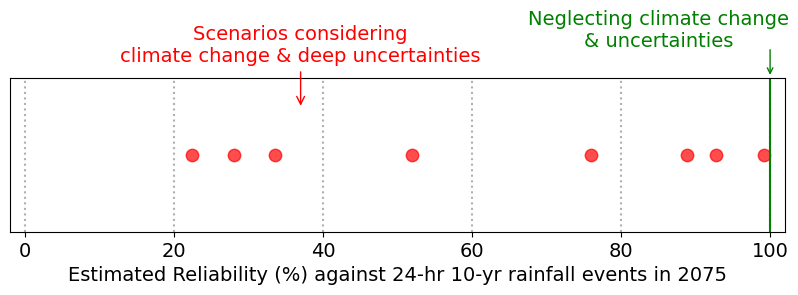

In [11]:
plot_stress_test(setup_file, fig5_swmm_path, fig5_network, fig5_figure_name)

## Figure 6: Runtime

The runtime difference for different approaches (seconds):
Network 5: BruteForce: 30662.93, PipeByPipe: 8634.32, SystemSF: 70.15, FunctionSF: 786.22
Network 9: BruteForce: 0.00, PipeByPipe: 20503.87, SystemSF: 107.95, FunctionSF: 2025.73
Network 16: BruteForce: 0.00, PipeByPipe: 287963.92, SystemSF: 370.31, FunctionSF: 4448.06
Network 23: BruteForce: 0.00, PipeByPipe: 559753.04, SystemSF: 721.40, FunctionSF: 8343.05
Network 37: BruteForce: 0.00, PipeByPipe: 1319916.09, SystemSF: 1733.03, FunctionSF: 20529.01
Network 49: BruteForce: 0.00, PipeByPipe: 3663096.33, SystemSF: 3033.06, FunctionSF: 35859.27
Network 62: BruteForce: 0.00, PipeByPipe: 6946131.59, SystemSF: 4751.85, FunctionSF: 57429.00
Network 76: BruteForce: 0.00, PipeByPipe: 12083246.12, SystemSF: 6710.97, FunctionSF: 88388.17
Network 84: BruteForce: 0.00, PipeByPipe: 15862710.30, SystemSF: 8254.76, FunctionSF: 108069.20
Network 100: BruteForce: 0.00, PipeByPipe: 25484750.89, SystemSF: 10563.12, FunctionSF: 129640.40
Network 1

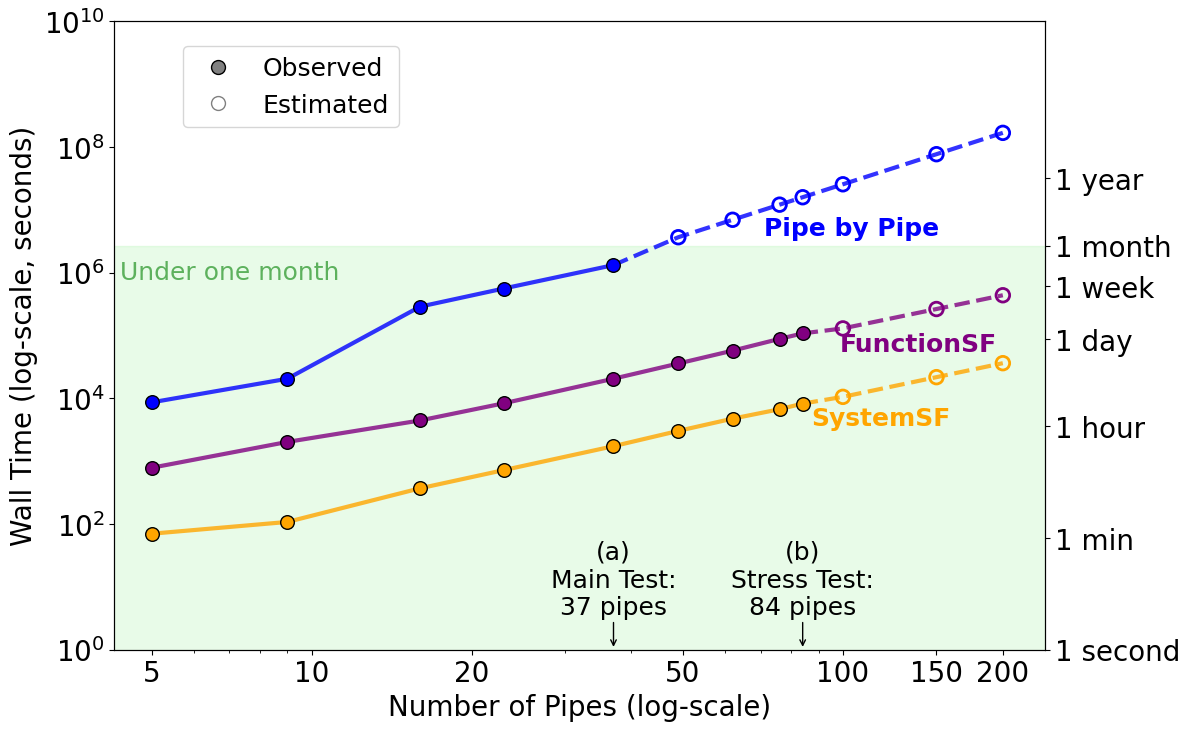

In [12]:
plot_runtime(fig6_n_obj, fig6_network, fig6_swmm_folder, fig6_figure_name)

## Figure 7: Two obj trade-offs

Design with reliability >= 90% and lowest cost:
Reliability (%)                  9.030000e+01
Robustness (%)                   7.500000e+01
System overflow volume (ft^3)    2.566291e+03
Cost ($)                         1.334482e+06
Cost ($/ft)                      2.109600e+02
Name: 125, dtype: float64
Design with reliability >= 90% and lowest cost:
Reliability (%)                  9.070000e+01
Robustness (%)                   6.250000e+01
System overflow volume (ft^3)    4.141088e+03
Cost ($)                         1.406646e+06
Cost ($/ft)                      2.223678e+02
Name: 129, dtype: float64
Design with reliability >= 90% and lowest cost:
Reliability (%)                  9.020000e+01
Robustness (%)                   6.250000e+01
System overflow volume (ft^3)    2.580426e+03
Cost ($)                         1.419089e+06
System SF                        1.215297e+00
Cost ($/ft)                      2.243349e+02
Name: 66, dtype: float64
Federal manual design did not exactly match

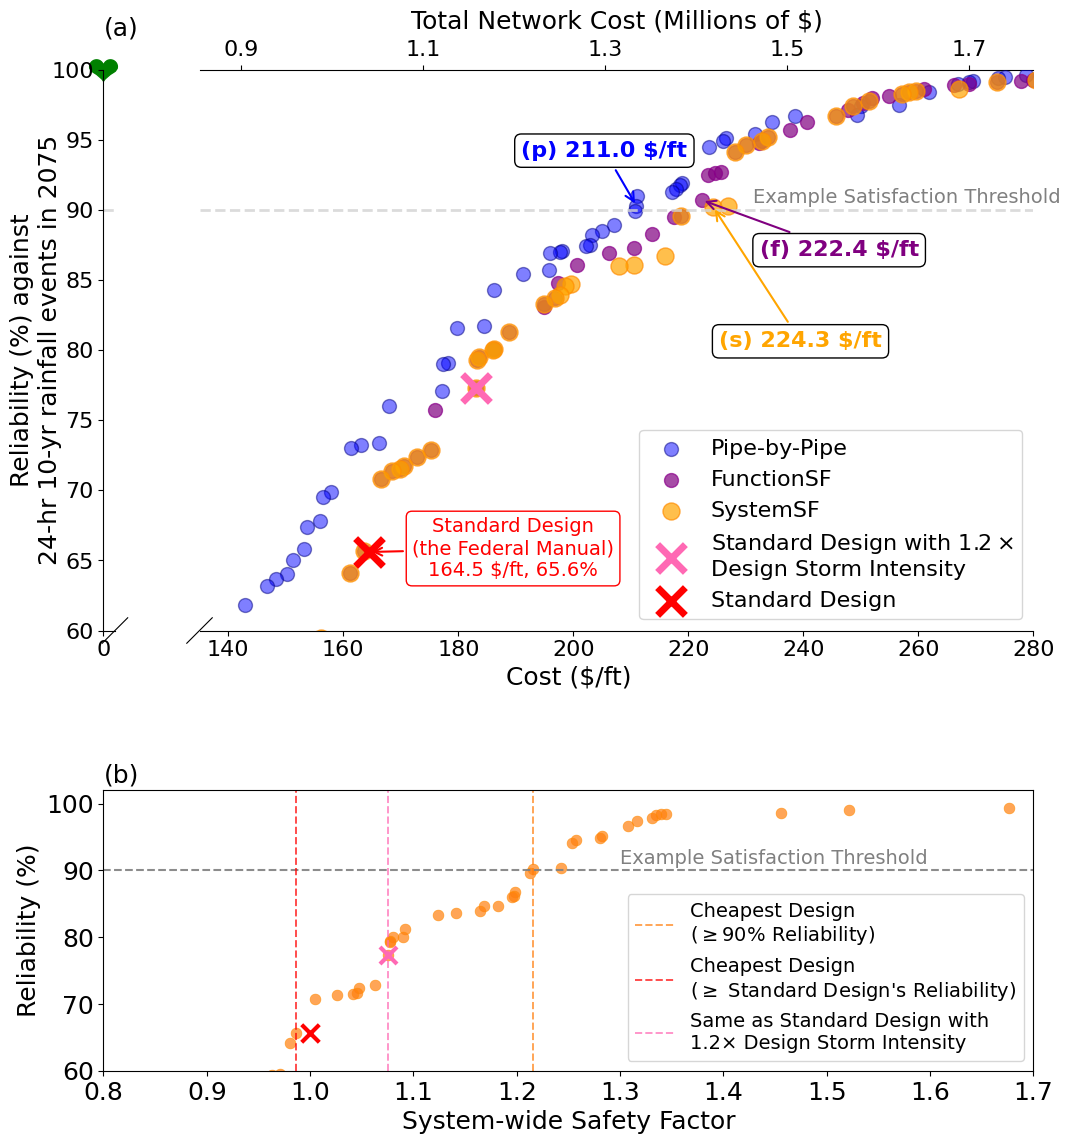

[(Reliability (%)                  9.030000e+01
  Robustness (%)                   7.500000e+01
  System overflow volume (ft^3)    2.566291e+03
  Cost ($)                         1.334482e+06
  Cost ($/ft)                      2.109600e+02
  Name: 125, dtype: float64,
  'PipeByPipe'),
 (Reliability (%)                  9.070000e+01
  Robustness (%)                   6.250000e+01
  System overflow volume (ft^3)    4.141088e+03
  Cost ($)                         1.406646e+06
  Cost ($/ft)                      2.223678e+02
  Name: 129, dtype: float64,
  'FunctionSF'),
 (Reliability (%)                  9.020000e+01
  Robustness (%)                   6.250000e+01
  System overflow volume (ft^3)    2.580426e+03
  Cost ($)                         1.419089e+06
  System SF                        1.215297e+00
  Cost ($/ft)                      2.243349e+02
  Name: 66, dtype: float64,
  'SystemSF')]

In [13]:
plot_obj_two_panel(
    figure_name=fig7_figure_name, 
    n_obj=4, 
    network=fig7_network, 
    paths=fig7_paths,
    UDD=fig7_UDD, 
    UDD_20prec=fig7_UDD_20prec,
    swmm_folder=fig7_swmm_folder, 
    cost_per_ft=True,
    report=90
)

## Figure 8: 4-obj Parallel plot

In [14]:
df_PBP,  df_FunctionSF, df_SF, report_list = load_data(fig8_swmm_folder, fig8_network, fig8_results_path, fig8_report)
report_list = {key: pd.DataFrame([value], columns=obj_name) for key, value in report_list.items()}

df_PBP_filtered = df_PBP[
    (df_PBP['Reliability (%)'] >= report_list['Standard']['Reliability (%)'].iloc[0]) &
    (df_PBP['Robustness (%)'] >= report_list['Standard']['Robustness (%)'].iloc[0]) &
    (df_PBP['Overflow volume (k $ft^3$)'] <= report_list['Standard']['Overflow volume (k $ft^3$)'].iloc[0]) &
    (df_PBP['Cost ($/ft)'] <= report_list['Standard']['Cost ($/ft)'].iloc[0])
]

pairs = []
delta_rel = []

for i, row_i in df_PBP_filtered.iterrows():
    for j, row_j in df_PBP_filtered.iterrows():
        if i == j:
            continue
        if (
            row_i['Reliability (%)'] > row_j['Reliability (%)']
            and row_i['Overflow volume (k $ft^3$)'] > row_j['Overflow volume (k $ft^3$)']
        ):
            pairs.append((i, j))
            delta_rel.append(row_i['Reliability (%)'] - row_j['Reliability (%)'])

if pairs:
    i, j = pairs[delta_rel.index(max(delta_rel))]
    print(f"Found rows: {i} (first) and {j} (second)")
    print(
        df_PBP_filtered.loc[
            [i, j],
            ['Reliability (%)', 'Overflow volume (k $ft^3$)', 'Cost ($/ft)']
        ]
    )
else:
    print("No such pair found.")


# Add this pair to report_list
if pairs:
    report_list['Pareto-Improved Example One'] = df_PBP_filtered.loc[[i], obj_name]
    report_list['Pareto-Improved Example Two'] = df_PBP_filtered.loc[[j], obj_name]

SystemSF
Design with reliability >= 90% and lowest cost:
Reliability (%)           9.020000e+01
Robustness (%)            6.250000e+01
Overflow volume (ft^3)    2.580426e+03
Cost ($)                  1.419089e+06
System SF                 1.215297e+00
Cost ($/ft)               2.243349e+02
Name: 66, dtype: float64
Pipe-by-Pipe
Design with reliability >= 90% and lowest cost:
Reliability (%)           9.030000e+01
Robustness (%)            7.500000e+01
Overflow volume (ft^3)    2.566291e+03
Cost ($)                  1.334482e+06
Cost ($/ft)               2.109600e+02
Name: 125, dtype: float64
FunctionSF
Design with reliability >= 90% and lowest cost:
Reliability (%)           9.070000e+01
Robustness (%)            6.250000e+01
Overflow volume (ft^3)    4.141088e+03
Cost ($)                  1.406646e+06
Cost ($/ft)               2.223678e+02
Name: 129, dtype: float64
Found rows: 252 (first) and 300 (second)
     Reliability (%)  Overflow volume (k $ft^3$)  Cost ($/ft)
252             73.

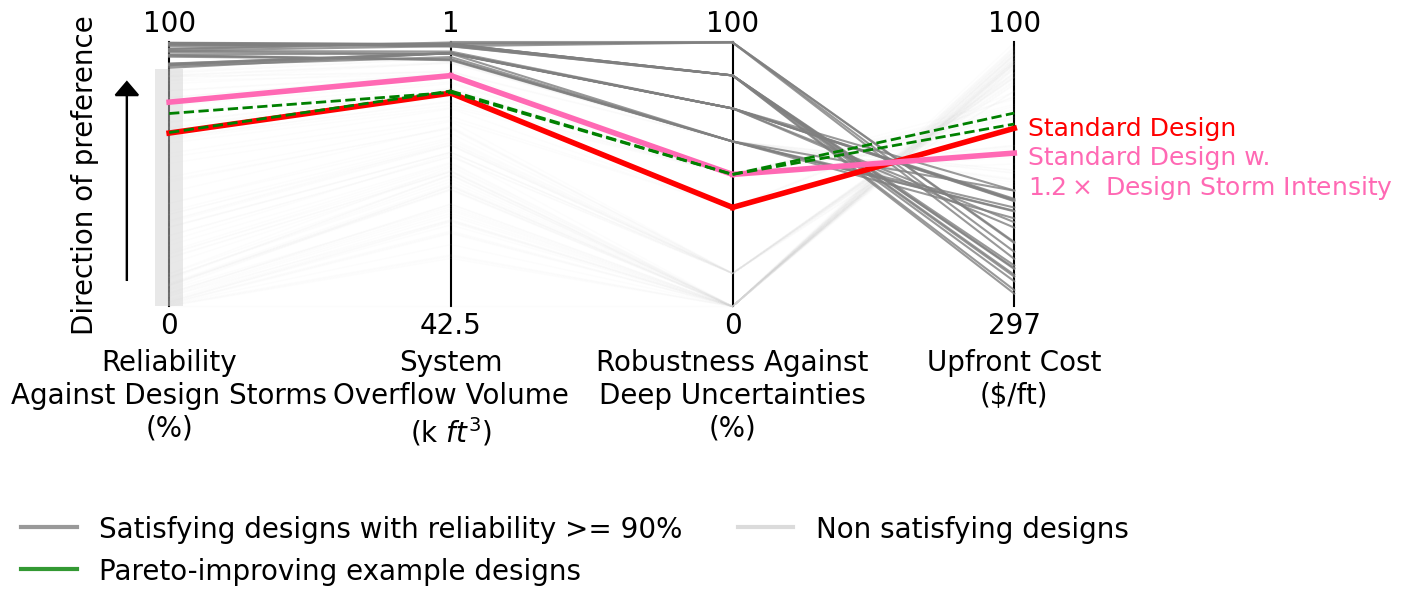

In [15]:

df_PBP = df_PBP.sort_values(by='Reliability (%)', ascending=True)

objs_reorg_list, tops, bottoms, report_list_reorg = reorganize_objs([df_PBP,  df_FunctionSF, df_SF], columns_axes, ideal_direction, minmaxs, report_list)

report_list_reorg_new = {'Standard': report_list_reorg['Standard'], 'Standard_20prec': report_list_reorg.get('Standard_20prec', pd.DataFrame(columns=obj_name)), 'Pareto-Improved Example One': report_list_reorg.get('Pareto-Improved Example One', pd.DataFrame(columns=obj_name)), 'Pareto-Improved Example Two': report_list_reorg.get('Pareto-Improved Example Two', pd.DataFrame(columns=obj_name))}



tops[[0,2]] = 100
bottoms[[0,2]] = 0
bottoms[1] = df_PBP['Overflow volume (k $ft^3$)'].max()

fig, ax = plt.subplots(1, 1, figsize=(15, 8))

brushing_dict = {0: (90, '>=')}

# Use the first reorganized dataframe which corresponds to Pipe-by-Pipe
df_pbp_reorg = objs_reorg_list[0]

color_dict_categorical = {'Satisfying designs with reliability >= 90%': 'grey', 'Pareto-improving example designs': 'green', 'Non satisfying designs': 'lightgrey'}
objs_with_category = df_PBP.copy()
objs_with_category['Category'] = ['Satisfying designs with reliability >= 90%' if objs_with_category['Reliability (%)'].iloc[i] >= 90 else 'Non satisfying designs' for i in range(objs_with_category.shape[0])]

custom_parallel_coordinates(
    objs=objs_with_category[columns_axes + ['Category']],
    objs_reorg=df_pbp_reorg,
    columns_axes=columns_axes,
    axis_labels=axis_labels,
    ideal_direction=ideal_direction,
    minmaxs=minmaxs,
    tops=tops,
    bottoms=bottoms,
    color_by_categorical='Category',
    color_dict_categorical=color_dict_categorical,
    colorbar=True,
    brushing_dict=brushing_dict,
    brushing_color='lightgrey',
    fontsize=20,
    ax=ax,
    report_data=report_list_reorg_new
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig(fig8_figure_name, bbox_inches='tight', dpi=300)
plt.show()

## Figure 9: Sensitivity Analysis

In [16]:
SAr_all = read_sobol_results(fig9_sobol_json_path_all)
SAr = read_sobol_results(fig9_sobol_json_path)

In [17]:
SAr_all_100 = {k1: {k2: (np.array(v) * 100).tolist() for k2, v in obj.items()} for k1, obj in SAr_all.items()}
SAr_100 = {k1: {k2: {k3: (np.array(v) * 100).tolist() for k3, v in inner.items()} for k2, inner in outer.items()} for k1, outer in SAr.items()}

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


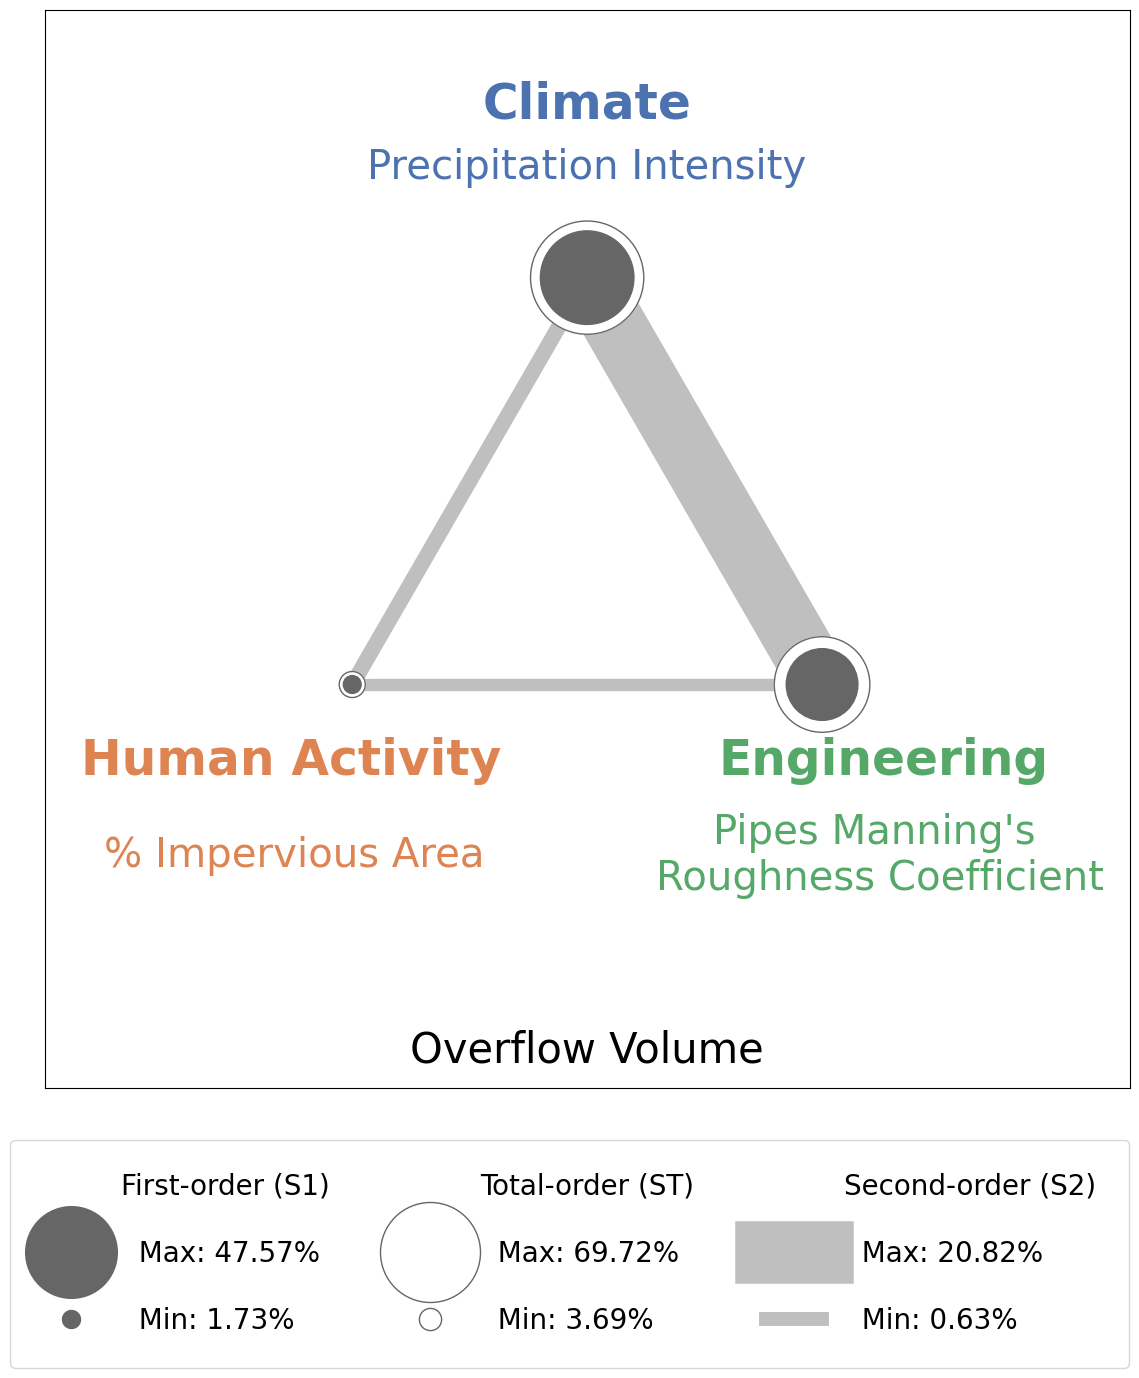

In [18]:
# --- Figure Setup ---
fig, ax1 = plt.subplots(figsize=(14, 14))
ax1.set_aspect('equal', adjustable='box')


# --- Data and Parameters ---
parameter_names = ['Precipitation Intensity', '% Impervious Area', 'Pipes Manning\'s \nRoughness Coefficient']
parameter_short_forms = ['Prec. Intensity', '% Imperv. Area', 'Roughness Coeff.']

grouped_para={
    'Climate': ['Precipitation Intensity'],
    'Human Activity': ['% Impervious Area'],
    'Engineering': ['Pipes Manning\'s \nRoughness Coefficient']
}

# --- Plot for SAr_all ---
grouped_radial_text(
    SAr_all['System overflow volume'],
    parameter_names,
    parameter_names,
    ax1,
    groups=grouped_para,
    threshold=0.0025,
    varNameMult=1.56,
    fontsize=29,
    gp_name=True,
    gp_fontsize=35,
    print_percentage=True,
    print_numbers=False,
)

ax1.annotate('Overflow Volume', xy=(0, -3.7), ha='center', va='center', fontsize=30)

# Legend for SAr_all
s1_all = SAr_all_100['System overflow volume']['S1']
st_all = SAr_all_100['System overflow volume']['ST']
s2_all = [val for row in SAr_all_100['System overflow volume']['S2'] for val in row]
s1_min, s1_max = min(s1_all), max(s1_all)
st_min, st_max = min(st_all), max(st_all)
s2_min, s2_max = np.nanmin(s2_all), np.nanmax(s2_all)

legend_elements1 = [
    Line2D([0], [0], marker='o', color='w', label='First-order (S1)'),
    Line2D([0], [0], marker='o', color='w', label=f'  Max: {s1_max:.2f}%', markerfacecolor='0.4', markersize=68),
    Line2D([0], [0], marker='o', color='w', label=f'  Min: {s1_min:.2f}%', markerfacecolor='0.4', markersize=15),
    Line2D([0], [0], marker='o', color='w', label='Total-order (ST)'),
    Line2D([0], [0], marker='o', color='w', label=f'  Max: {st_max:.2f}%', markerfacecolor='w', markeredgecolor='0.4', markersize=72),
    Line2D([0], [0], marker='o', color='w', label=f'  Min: {st_min:.2f}%', markerfacecolor='w', markeredgecolor='0.4', markersize=16),
    Line2D([0], [0], marker='o', color='w', label='Second-order (S2)'),
    Line2D([0], [0], color='0.75', lw=45, label=f'  Max: {s2_max:.2f}%'),
    Line2D([0], [0], color='0.75', lw=10, label=f'  Min: {s2_min:.2f}%'),
]
fig.legend(handles=legend_elements1, loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=20, labelspacing=1.4, columnspacing=2.6, borderpad=1.2)

plt.savefig(fig9_figure_name, bbox_inches='tight', dpi=300)
plt.show()